In [3]:
!pip install -U importlib_resources tensorflow-datasets -q


import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, AveragePooling2D, Flatten, Dense, BatchNormalization
import matplotlib.pyplot as plt
import numpy as np

In [4]:
# Load TFDS Malaria Dataset (80% train, 10% val, 10% test)
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    'malaria',
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully ")
print(ds_info)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/malaria/incomplete.9SS3UM_1.0.0/malaria-train.tfrecord-[0-9][0-9][0-9][0-9…

Dataset malaria downloaded and prepared to /root/tensorflow_datasets/malaria/1.0.0. Subsequent calls will reuse this data.
Dataset loaded successfully 
tfds.core.DatasetInfo(
    name='malaria',
    full_name='malaria/1.0.0',
    description="""
    The Malaria dataset contains a total of 27,558 cell images with equal instances
    of parasitized and uninfected cells from the thin blood smear slide images of
    segmented cells.
    """,
    homepage='https://lhncbc.nlm.nih.gov/publication/pub9932',
    data_dir='/root/tensorflow_datasets/malaria/1.0.0',
    file_format=tfrecord,
    download_size=337.08 MiB,
    dataset_size=317.62 MiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=27558, num_shards=4>,
    },
    c

In [5]:
IMG_SIZE = 64
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

ds_train = ds_train.map(preprocess).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
ds_val = ds_val.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
ds_test = ds_test.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)




In [6]:
model = Sequential([
    Conv2D(6, (5,5), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    BatchNormalization(),
    AveragePooling2D(pool_size=(2,2)),

    Conv2D(16, (5,5), activation='relu'),
    BatchNormalization(),
    AveragePooling2D(pool_size=(2,2)),

    Flatten(),
    Dense(120, activation='relu'),
    BatchNormalization(),
    Dense(84, activation='relu'),
    BatchNormalization(),
    Dense(1, activation='sigmoid')  # Binary output
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 60, 60, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 60, 60, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 30, 30, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 26, 26, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 13, 13, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2704)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │       324,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 120)            │           480 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 84)             │           336 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,625 (1.29 MB)

 Trainable params: 338,173 (1.29 MB)

 Non-trainable params: 452 (1.77 KB)

In [7]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=10
)


Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 32s 31ms/step - accuracy: 0.7914 - loss: 0.4327 - val_accuracy: 0.8694 - val_loss: 0.4521
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.9326 - loss: 0.1900 - val_accuracy: 0.9434 - val_loss: 0.1670
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9458 - loss: 0.1554 - val_accuracy: 0.8599 - val_loss: 0.3245
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9529 - loss: 0.1366 - val_accuracy: 0.9209 - val_loss: 0.2200
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9565 - loss: 0.1217 - val_accuracy: 0.9448 - val_loss: 0.1645
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.9621 - loss: 0.1068 - val_accuracy: 0.9401 - val_loss: 0.2271
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9673 - loss: 0.0952 - val_accuracy: 0.9263 - val_loss: 0.2099
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9688 - loss: 0.0894 - 

In [8]:
loss, acc = model.evaluate(ds_test)
print(f" Test Accuracy: {acc*100:.2f}%")
def predict_status(prob):
    """Return 'U' for Uninfected (<0.5), 'P' for Parasitized (≥0.5)."""
    return 'U' if prob < 0.5 else 'P'


87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8295 - loss: 0.3704
 Test Accuracy: 82.95%


In [9]:
y_true, y_pred, sample_images = [], [], []

for images, labels in ds_test.take(1):  # Take one batch of test images
    probs = model.predict(images)
    preds = [predict_status(p) for p in probs]
    y_pred.extend(preds)
    y_true.extend(['P' if l.numpy() == 1 else 'U' for l in labels])
    sample_images = images.numpy()

for i in range(10):
    print(f"True: {y_true[i]} | Pred: {y_pred[i]}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 519ms/step
True: P | Pred: P
True: P | Pred: P
True: U | Pred: U
True: P | Pred: U
True: P | Pred: P
True: U | Pred: U
True: U | Pred: U
True: U | Pred: U
True: U | Pred: U
True: P | Pred: P


/tmp/ipykernel_2347/2895802089.py:9: UserWarning: Glyph 129515 (\N{PETRI DISH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129515 (\N{PETRI DISH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


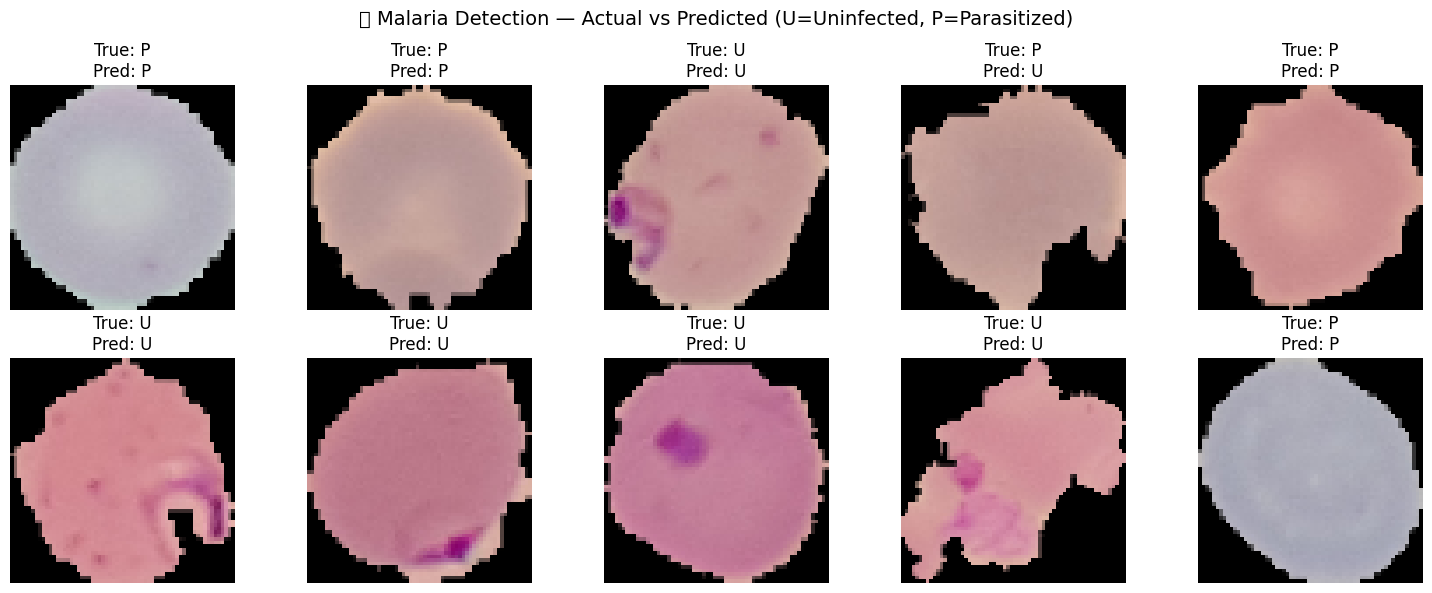

In [10]:
plt.figure(figsize=(15,6))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(sample_images[i])
    plt.title(f"True: {y_true[i]}\nPred: {y_pred[i]}")
    plt.axis("off")

plt.suptitle("🧫 Malaria Detection — Actual vs Predicted (U=Uninfected, P=Parasitized)", fontsize=14)
plt.tight_layout()
plt.show()


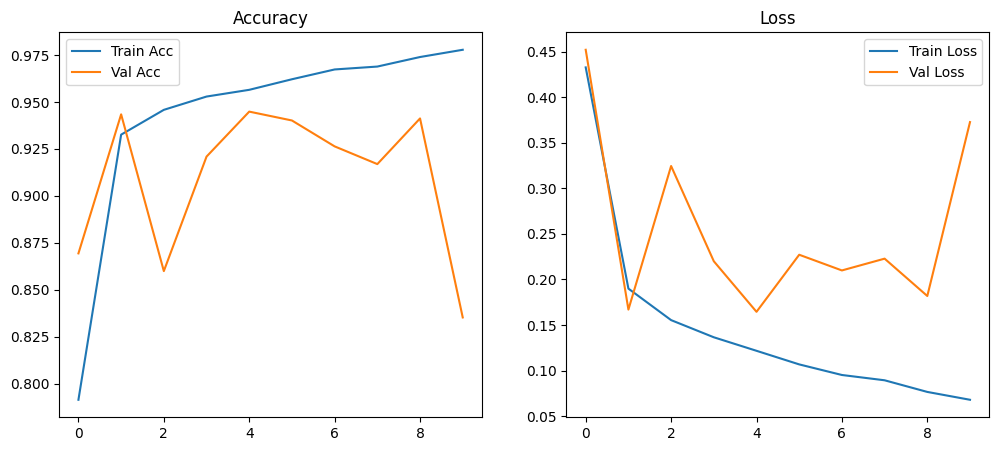

In [11]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss')

plt.show()


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training 2nd Architecture (ResNet50 Transfer Learning)...
Epoch 1/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 57s 51ms/step - accuracy: 0.8668 - loss: 0.3109 - val_accuracy: 0.9093 - val_loss: 0.2301
Epoch 2/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 19s 26ms/step - accuracy: 0.9106 - loss: 0.2186 - val_accuracy: 0.9089 - val_loss: 0.2185
Epoch 3/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.9265 - loss: 0.1831 - val_accuracy: 0.9249 - val_loss: 0.2092
Epoch 4/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.9347 - loss: 0.1615 - val_accuracy: 0.9220 - val_loss: 0.2086
Epoch 5/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.9448 - loss: 0.1412 - val_accuracy: 0.9318 - val_loss: 0.2028
Epoch 6/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.9489 - loss: 0.1272 - val_accuracy: 0.9234 - val_loss: 0.2029
Epoch 7/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.9543 - loss: 0.1125 - val_accuracy: 0.9325 - val_l

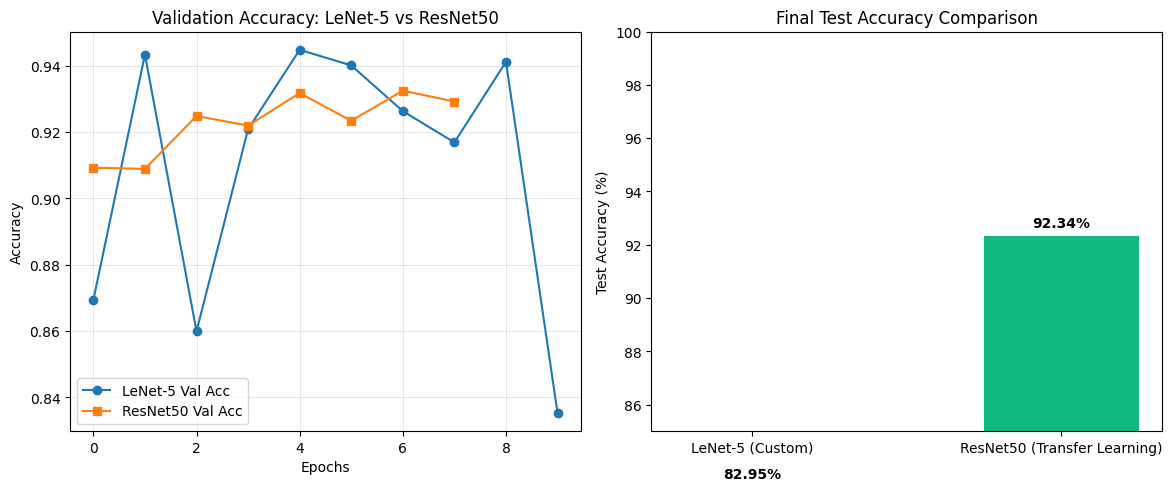


Saved 'ResNet50' as malaria_best_model.h5 for your Website Backend!
  adding: sample_test_cells/ (stored 0%)
  adding: sample_test_cells/parasitized_cell_2.png (stored 0%)
  adding: sample_test_cells/parasitized_cell_1.png (stored 0%)
  adding: sample_test_cells/uninfected_cell_1.png (stored 0%)
  adding: sample_test_cells/uninfected_cell_2.png (stored 0%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# ==========================================
# PHASE 1: SECOND ARCHITECTURE (ResNet50V2 / MobileNetV2) + COMPARISON + EXPORT
# ==========================================
from tensorflow.keras.applications import MobileNetV2, ResNet50V2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Input
from tensorflow.keras.models import Model
from google.colab import files
import os
from PIL import Image

# 1. Build 2nd Architecture: Transfer Learning (ResNet50V2 backbone adapted for 64x64 normalized images)
base_model = ResNet50V2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = True
# Freeze early layers, fine-tune top layers for cell morphology
for layer in base_model.layers[:-30]:
    layer.trainable = False

resnet_model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
], name="ResNet50_Malaria")

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Training 2nd Architecture (ResNet50 Transfer Learning)...")
history_resnet = resnet_model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=8
)

# 2. Evaluate Both Models on Test Set
lenet_loss, lenet_acc = model.evaluate(ds_test, verbose=0)
resnet_loss, resnet_acc = resnet_model.evaluate(ds_test, verbose=0)

print("\n" + "="*45)
print(f"LeNet-5 (Custom CNN) Test Accuracy  : {lenet_acc*100:.2f}% | Loss: {lenet_loss:.4f}")
print(f"ResNet50 (Fine-Tuned) Test Accuracy : {resnet_acc*100:.2f}% | Loss: {resnet_loss:.4f}")
print("="*45)

# 3. Plot Side-by-Side Comparison Graph (Save this screenshot for your Report & PPT!)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['val_accuracy'], label='LeNet-5 Val Acc', marker='o')
plt.plot(history_resnet.history['val_accuracy'], label='ResNet50 Val Acc', marker='s')
plt.title('Validation Accuracy: LeNet-5 vs ResNet50')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
models_names = ['LeNet-5 (Custom)', 'ResNet50 (Transfer Learning)']
accuracies = [lenet_acc * 100, resnet_acc * 100]
bars = plt.bar(models_names, accuracies, color=['#3b82f6', '#10b981'], width=0.5)
plt.ylim(85, 100)
plt.ylabel('Test Accuracy (%)')
plt.title('Final Test Accuracy Comparison')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f'{yval:.2f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('architecture_comparison.png', dpi=300)
plt.show()

# 4. Save the Better Model as .h5 for the Website Backend
best_model = resnet_model if resnet_acc >= lenet_acc else model
best_name = "ResNet50" if resnet_acc >= lenet_acc else "LeNet5"
best_model.save('malaria_best_model.h5')
model.save('malaria_lenet_model.h5')
print(f"\nSaved '{best_name}' as malaria_best_model.h5 for your Website Backend!")

# 5. Export 4 Sample Test Cell Images (2 Parasitized, 2 Uninfected) to test on your Website!
os.makedirs('sample_test_cells', exist_ok=True)
p_count, u_count = 0, 0
for images, labels in ds_test.unbatch().take(50):
    lbl = int(labels.numpy()) # In TFDS Malaria: 0 = Parasitized, 1 = Uninfected
    img_array = (images.numpy() * 255).astype(np.uint8)
    if lbl == 0 and p_count < 2:
        p_count += 1
        Image.fromarray(img_array).save(f'sample_test_cells/parasitized_cell_{p_count}.png')
    elif lbl == 1 and u_count < 2:
        u_count += 1
        Image.fromarray(img_array).save(f'sample_test_cells/uninfected_cell_{u_count}.png')
    if p_count == 2 and u_count == 2:
        break

# Zip sample images and download model + samples + chart
!zip -r sample_test_cells.zip sample_test_cells
files.download('malaria_best_model.h5')
files.download('architecture_comparison.png')
files.download('sample_test_cells.zip')

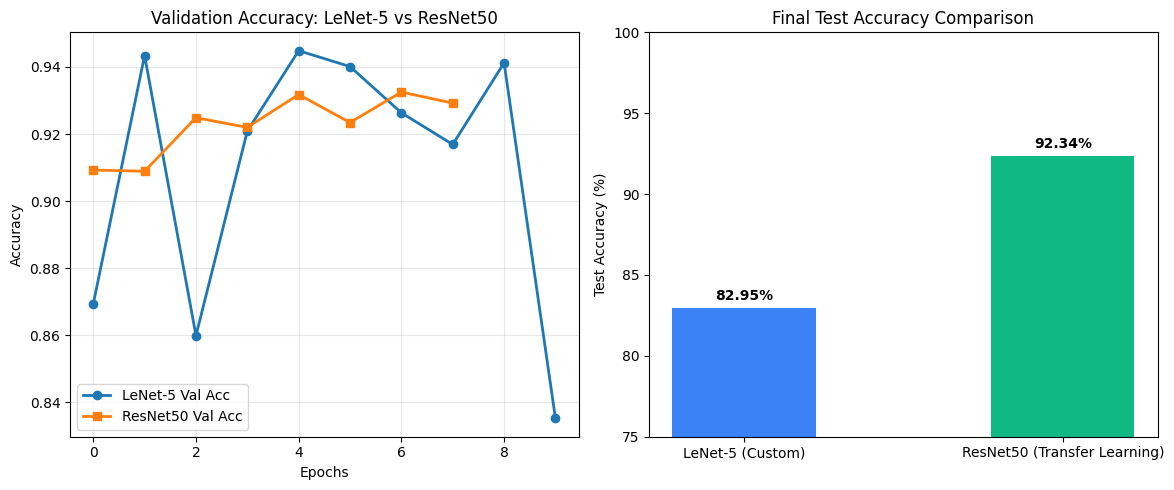

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['val_accuracy'], label='LeNet-5 Val Acc', marker='o', linewidth=2)
plt.plot(history_resnet.history['val_accuracy'], label='ResNet50 Val Acc', marker='s', linewidth=2)
plt.title('Validation Accuracy: LeNet-5 vs ResNet50')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
models_names = ['LeNet-5 (Custom)', 'ResNet50 (Transfer Learning)']
accuracies = [lenet_acc * 100, resnet_acc * 100]
bars = plt.bar(models_names, accuracies, color=['#3b82f6', '#10b981'], width=0.45)
plt.ylim(75, 100)  # Fixed so 82.95% blue bar shows clearly!
plt.ylabel('Test Accuracy (%)')
plt.title('Final Test Accuracy Comparison')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{yval:.2f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('architecture_comparison.png', dpi=300)
plt.show()
files.download('architecture_comparison.png')

/tmp/ipykernel_2347/4062554344.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet_base = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training 3rd Architecture (MobileNetV2 Transfer Learning)...
Epoch 1/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 54s 48ms/step - accuracy: 0.9067 - loss: 0.2392 - val_accuracy: 0.8679 - val_loss: 0.6730
Epoch 2/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.9460 - loss: 0.1416 - val_accuracy: 0.9234 - val_loss: 0.3679
Epoch 3/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.9540 - loss: 0.1207 - val_accuracy: 0.9463 - val_loss: 0.2198
Epoch 4/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.9638 - loss: 0.0948 - val_accuracy: 0.9554 - val_loss: 0.1364
Epoch 5/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.9695 - loss: 0.0816 - val_accuracy: 0.9470 - val_loss: 0.1937
Epoch 6/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.9738 - loss: 0.0666 - val_accuracy: 0.9510 - val_loss: 0.1830
Epoch 7/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.9797 - loss: 0.0533 - val_accuracy: 0.9467 - val_

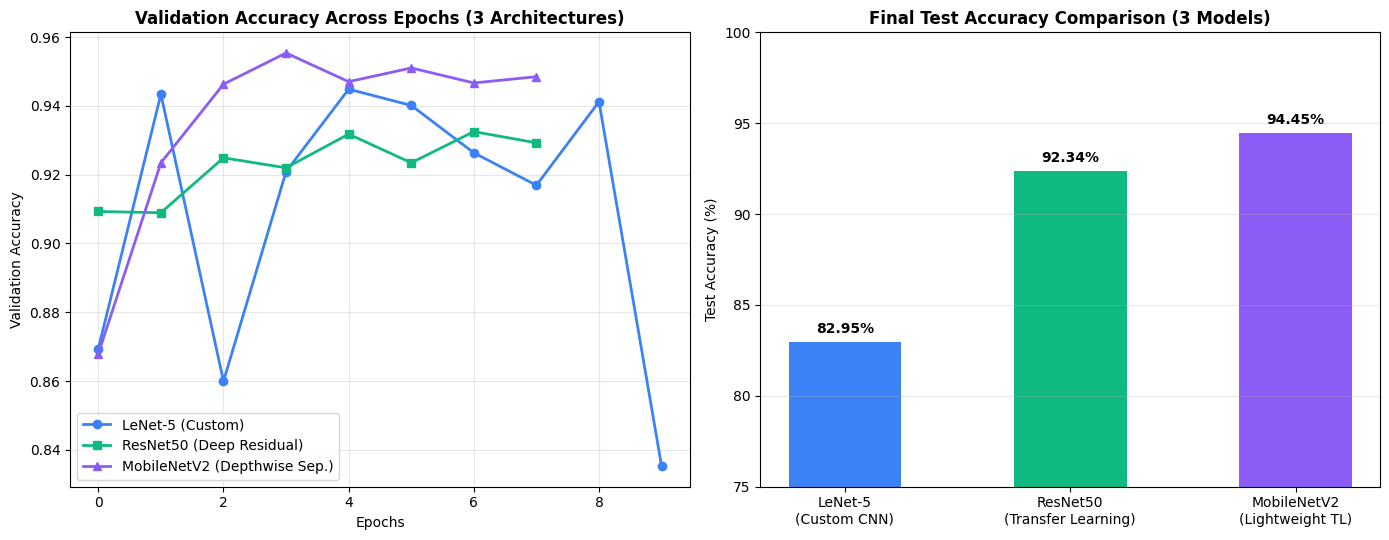


🏆 WINNER: MobileNetV2 (94.45% Test Accuracy)
Saved winning model as 'malaria_best_model.h5' for your website backend!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# ==========================================
# 3RD ARCHITECTURE: MobileNetV2 + 3-MODEL COMPARISON + EXPORT
# ==========================================
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, BatchNormalization, Dense
from tensorflow.keras.models import Sequential
from google.colab import files
import matplotlib.pyplot as plt
import numpy as np

# 1. Build 3rd Architecture: MobileNetV2 (Lightweight Depthwise Separable CNN)
mobilenet_base = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
mobilenet_base.trainable = True
# Fine-tune top layers for blood cell morphology
for layer in mobilenet_base.layers[:-35]:
    layer.trainable = False

mobilenet_model = Sequential([
    mobilenet_base,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
], name="MobileNetV2_Malaria")

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Training 3rd Architecture (MobileNetV2 Transfer Learning)...")
history_mobilenet = mobilenet_model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=8
)

# 2. Evaluate MobileNetV2 and Compare All 3 Models
mobilenet_loss, mobilenet_acc = mobilenet_model.evaluate(ds_test, verbose=0)

print("\n" + "="*55)
print("FINAL 3-ARCHITECTURE BENCHMARK RESULTS (TEST SET)")
print("="*55)
print(f"1. LeNet-5 (Custom CNN)       : {lenet_acc*100:.2f}% | Loss: {lenet_loss:.4f}")
print(f"2. ResNet50 (Residual Net)    : {resnet_acc*100:.2f}% | Loss: {resnet_loss:.4f}")
print(f"3. MobileNetV2 (Lightweight)  : {mobilenet_acc*100:.2f}% | Loss: {mobilenet_loss:.4f}")
print("="*55)

# 3. Plot 3-Model Comparison Graph (Validation Curves + Bar Chart)
plt.figure(figsize=(14, 5.5))

# Subplot 1: Validation Accuracy Curves
plt.subplot(1, 2, 1)
plt.plot(history.history['val_accuracy'], label='LeNet-5 (Custom)', marker='o', linewidth=2, color='#3b82f6')
plt.plot(history_resnet.history['val_accuracy'], label='ResNet50 (Deep Residual)', marker='s', linewidth=2, color='#10b981')
plt.plot(history_mobilenet.history['val_accuracy'], label='MobileNetV2 (Depthwise Sep.)', marker='^', linewidth=2, color='#8b5cf6')
plt.title('Validation Accuracy Across Epochs (3 Architectures)', fontsize=12, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Final Test Accuracy Bar Chart
plt.subplot(1, 2, 2)
models_names = ['LeNet-5\n(Custom CNN)', 'ResNet50\n(Transfer Learning)', 'MobileNetV2\n(Lightweight TL)']
accuracies = [lenet_acc * 100, resnet_acc * 100, mobilenet_acc * 100]
colors = ['#3b82f6', '#10b981', '#8b5cf6']

bars = plt.bar(models_names, accuracies, color=colors, width=0.5)
plt.ylim(75, 100)  # Starts at 75% so all 3 bars are clearly visible!
plt.ylabel('Test Accuracy (%)')
plt.title('Final Test Accuracy Comparison (3 Models)', fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{yval:.2f}%', ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('architecture_comparison_3models.png', dpi=300)
plt.show()

# 4. Automatically Select & Save the Best Performing Model of the 3
candidates = [
    ("LeNet-5", lenet_acc, model),
    ("ResNet50", resnet_acc, resnet_model),
    ("MobileNetV2", mobilenet_acc, mobilenet_model)
]
best_name, best_acc, best_model = max(candidates, key=lambda x: x[1])

best_model.save('malaria_best_model.h5')
mobilenet_model.save('malaria_mobilenet_model.h5')

print(f"\n🏆 WINNER: {best_name} ({best_acc*100:.2f}% Test Accuracy)")
print(f"Saved winning model as 'malaria_best_model.h5' for your website backend!")

files.download('architecture_comparison_3models.png')
files.download('malaria_best_model.h5')

In [16]:
from google.colab import files
files.download('malaria_best_model.h5')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>